## 微调

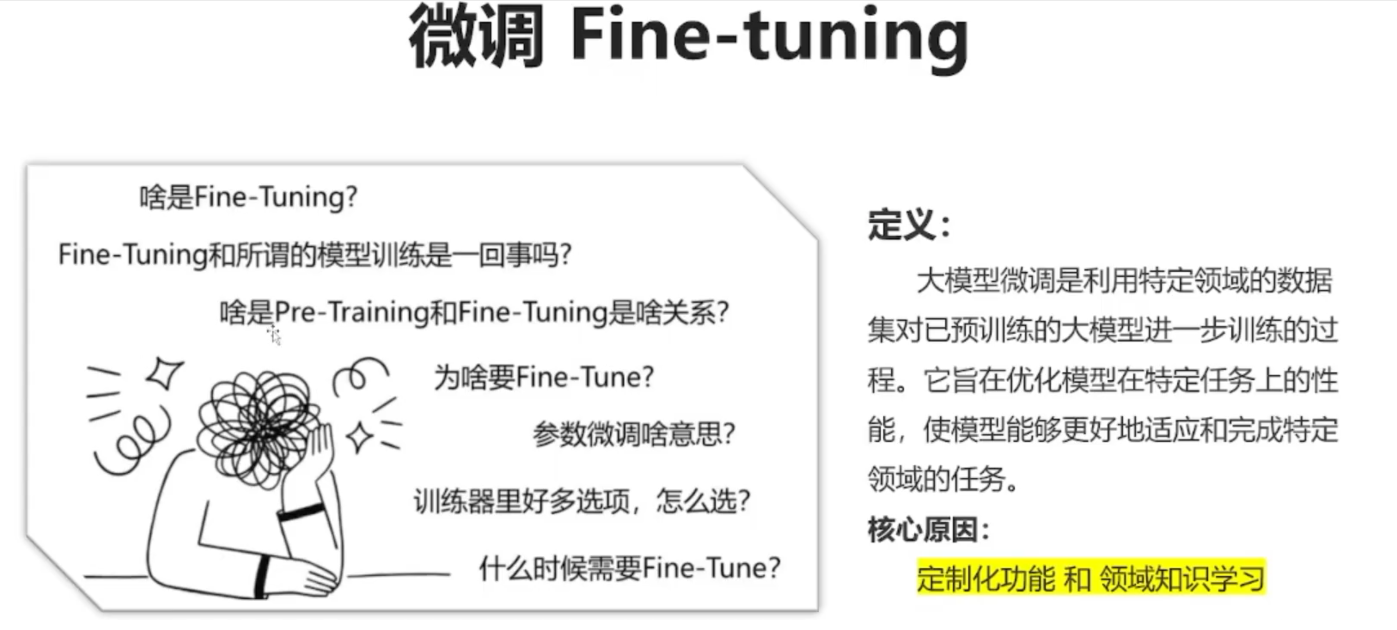

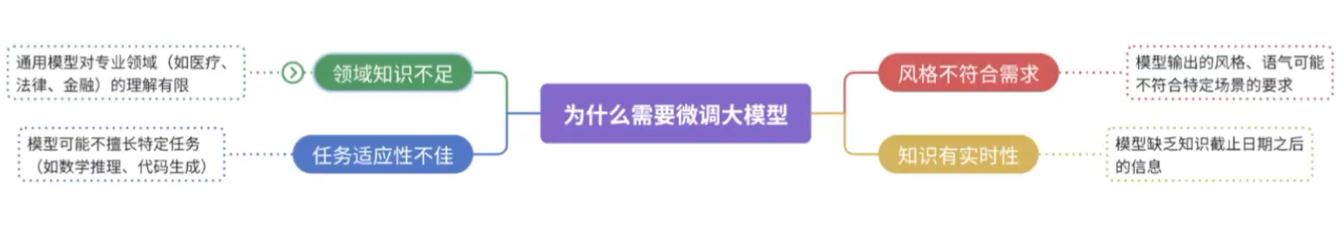

## 微调主要解决两方面问题

1.知识注入：让模型掌握特定领域或业务中的专业知识。<br>
2.行为对齐：让模型按照指定的任务、格式、语气和规则输出结果。<br>
3.突破知识截止：补充预训练结束后出现的新知识，或特定领域的私有知识。（不过，更新时效性知识通常更适合使用 RAG；微调更擅长改变模型的行为模式和任务能力。）

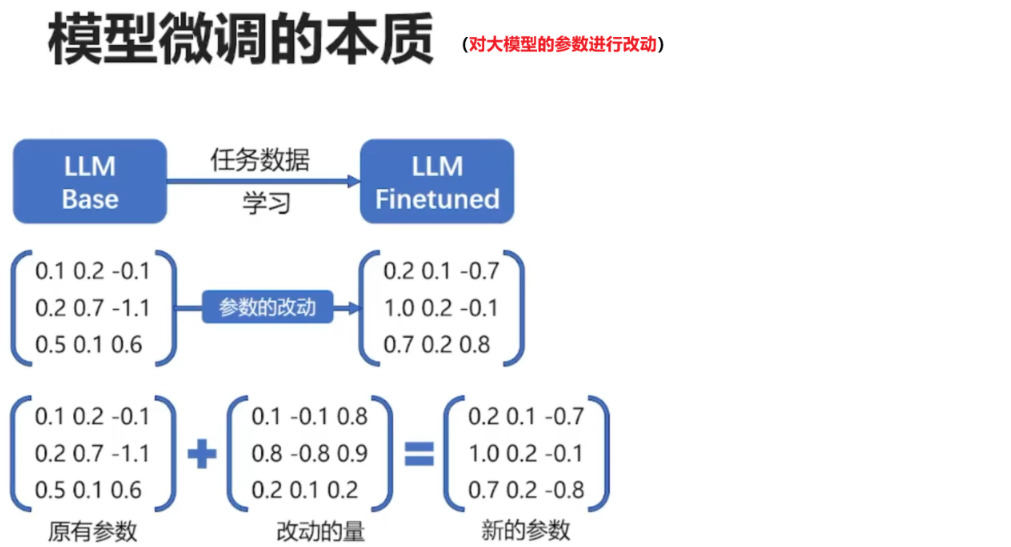

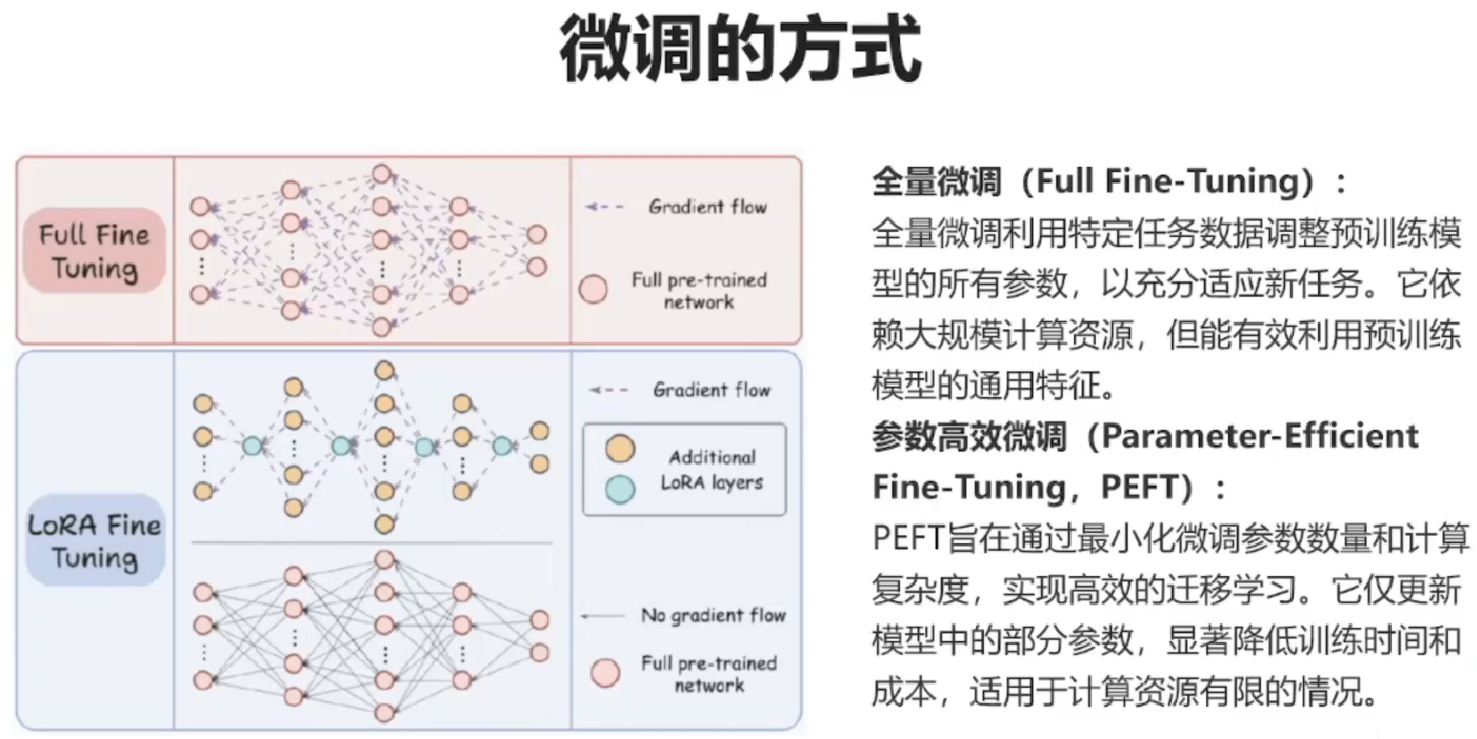

## 大模型参数高效微调的方法

大模型参数高效微调的方法包括LoRA(重点)、Prompt Tuning、BitFit、P-Tuning、Prefix-Tuning、Adapter和IA3等等，这些方法通过减少训练参数量或计算成本来实现高效微调，各有优缺点，需根据任务需求和资源选择

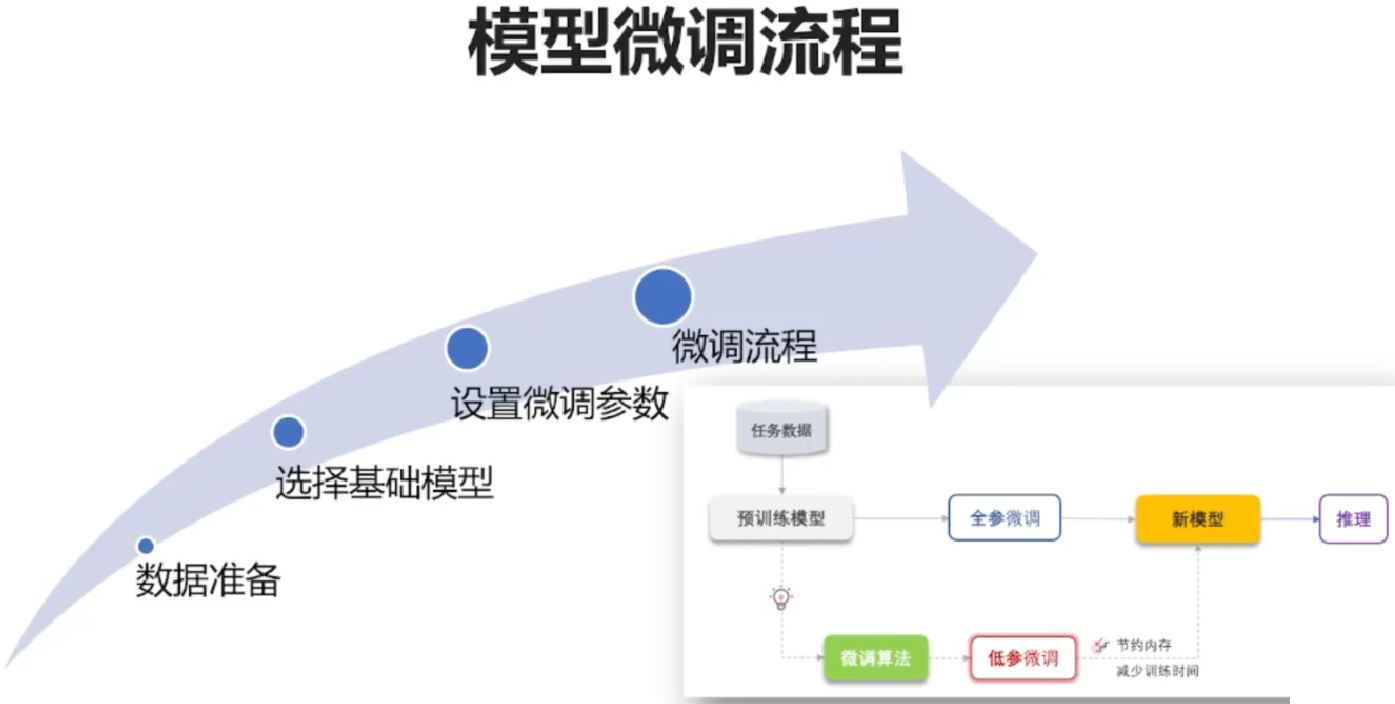

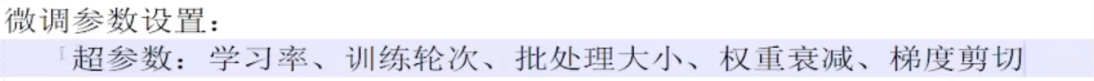

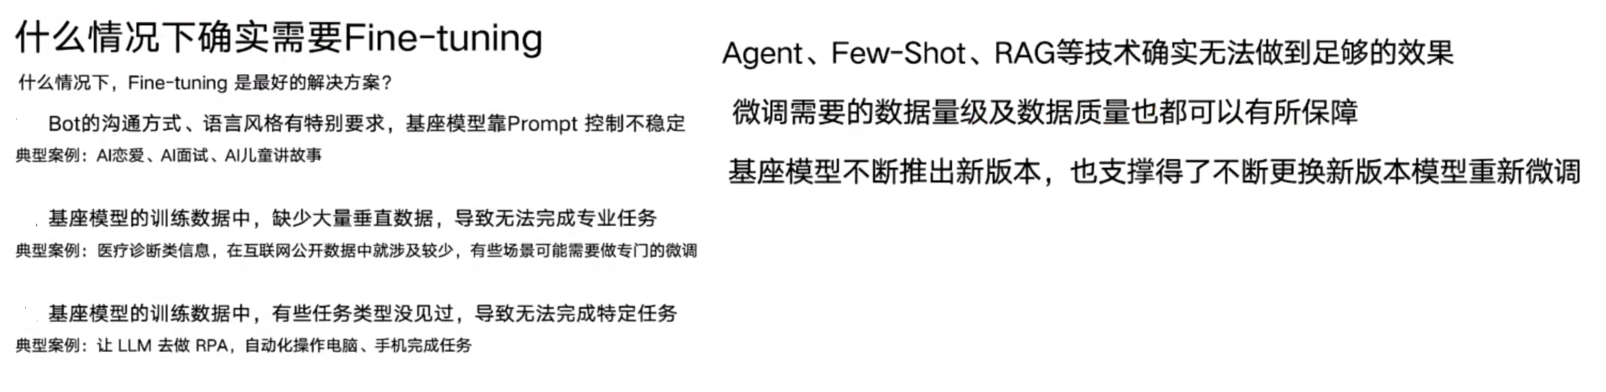

## LoRA 优势

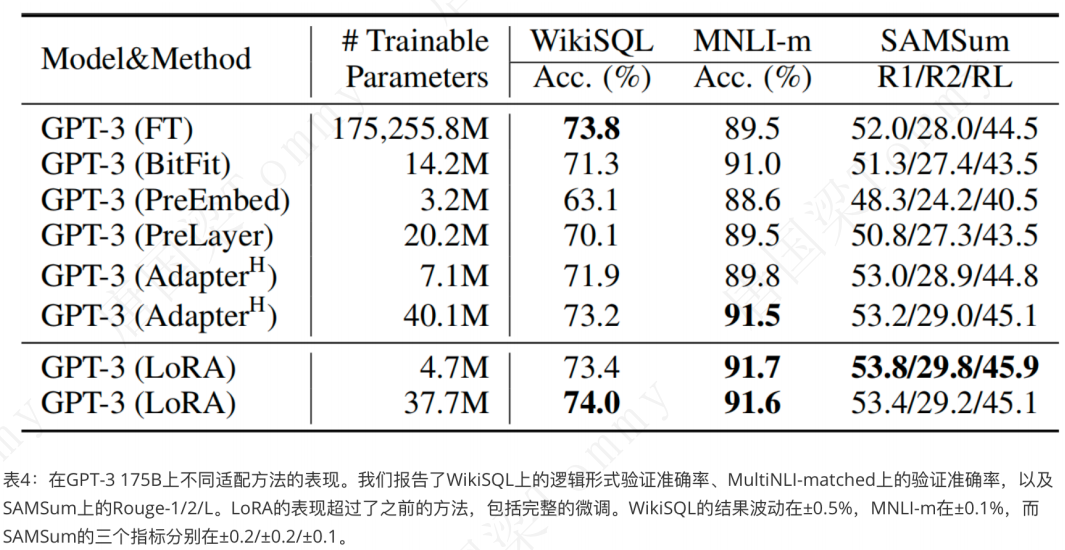

## LoRA(Low Rank Adaption--低秩适配)算法原理

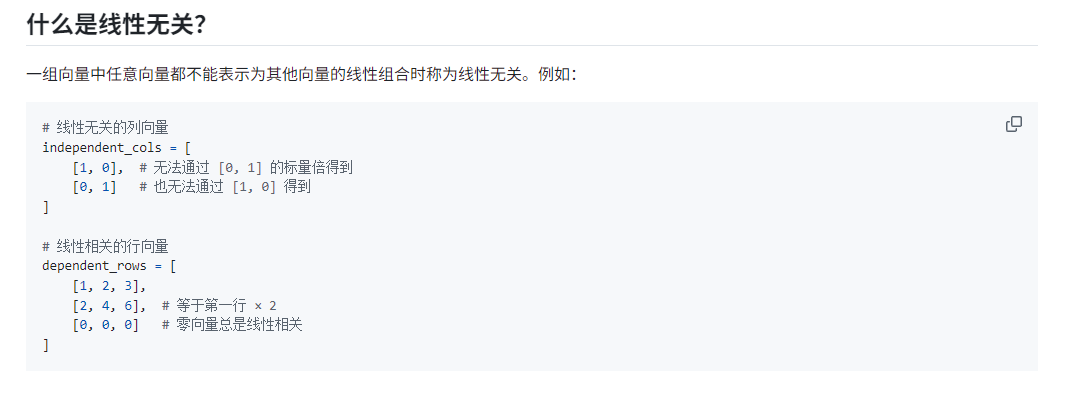

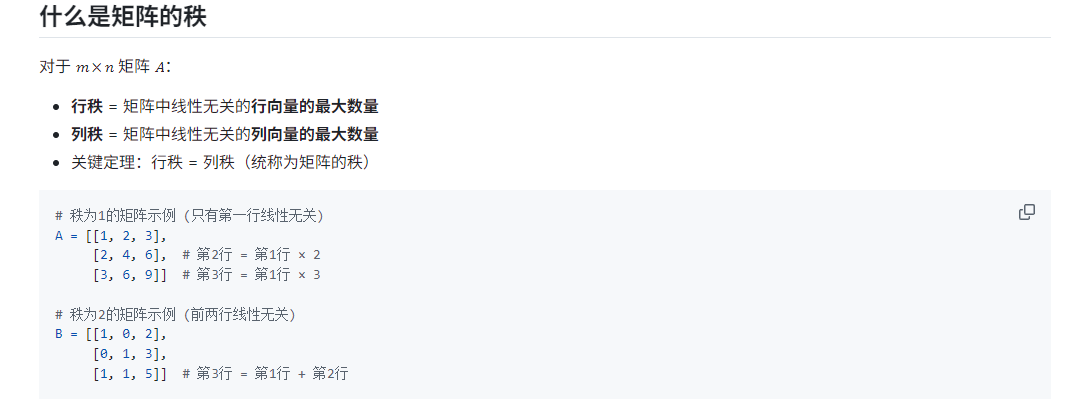

**一个矩阵的秩越大，它的信息含量就越大**

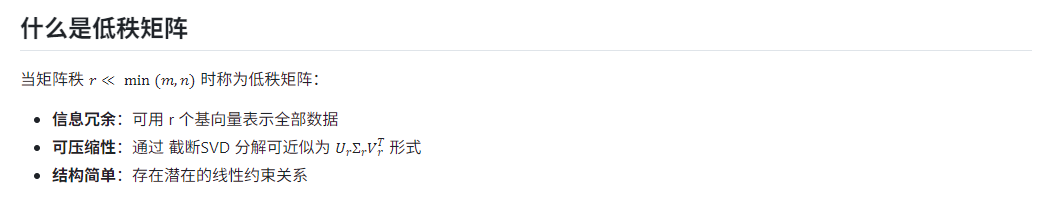

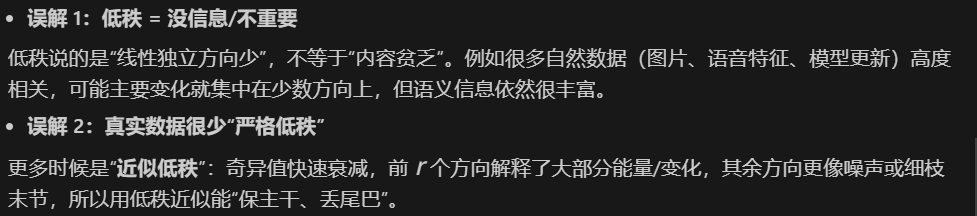

### Lora(低秩适配):把一个秩比较大的矩阵变成秩比较小的矩阵
LoRA（Low-Rank Adaptation, 低秩适配）：由微软于 2021 年提出，是一种高效微调大型语言模型（LLM）的技术。<br>
它通过在冻结的预训练模型权重旁添加小型可训练的低秩矩阵，显著降低了微调过程中的计算和内存需求，无需重新训练整个模型。<br>

 LoRA 的核心思想是将预训练模型的权重矩阵分解为两个低秩矩阵的乘积。假设原有矩阵权重为W微调过程中拆解成两个低秩矩阵A、B的乘积，冻结原有矩阵`+`两个低秩矩阵的乘积来适应新的任务。 (在不修改模型参数的情况下，通过添加一个额外的可训练模块，对模型行为进行小范围、有针对性的调整。)<br>

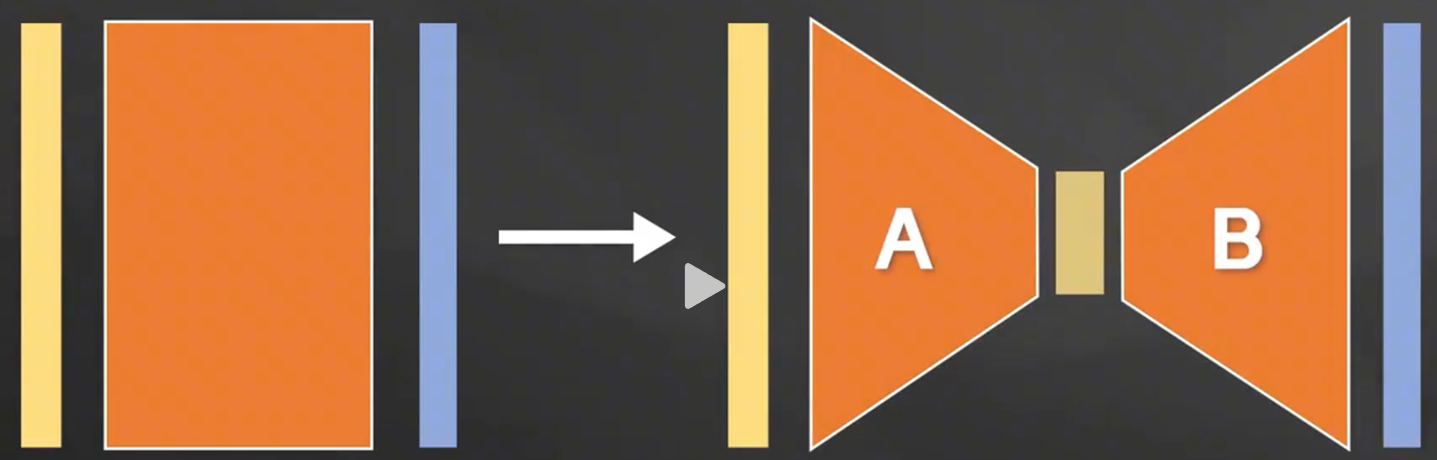<br>




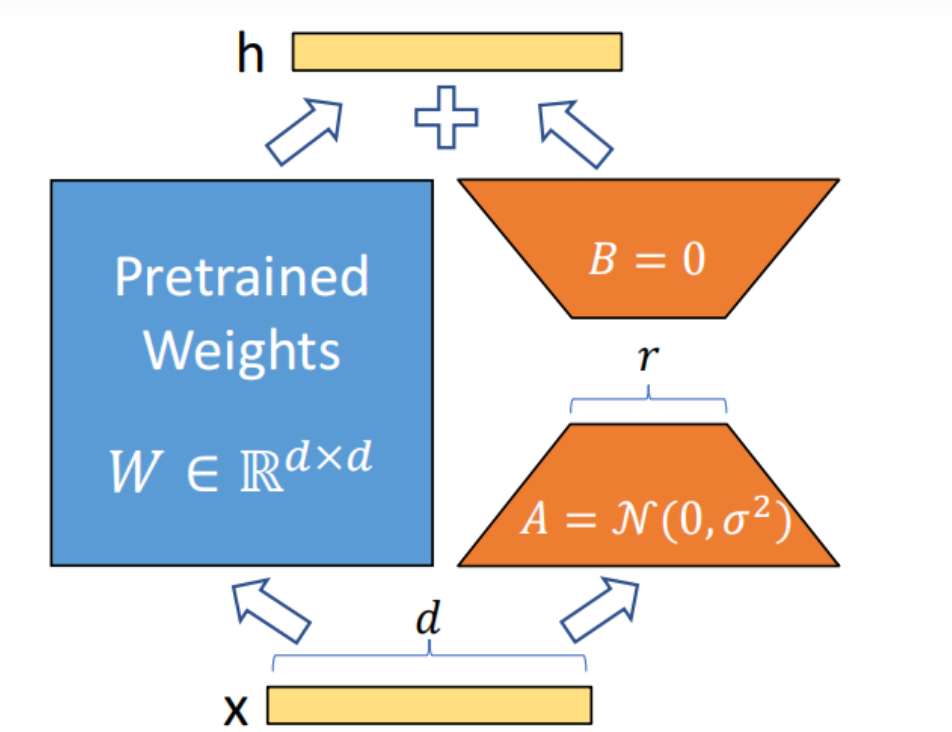

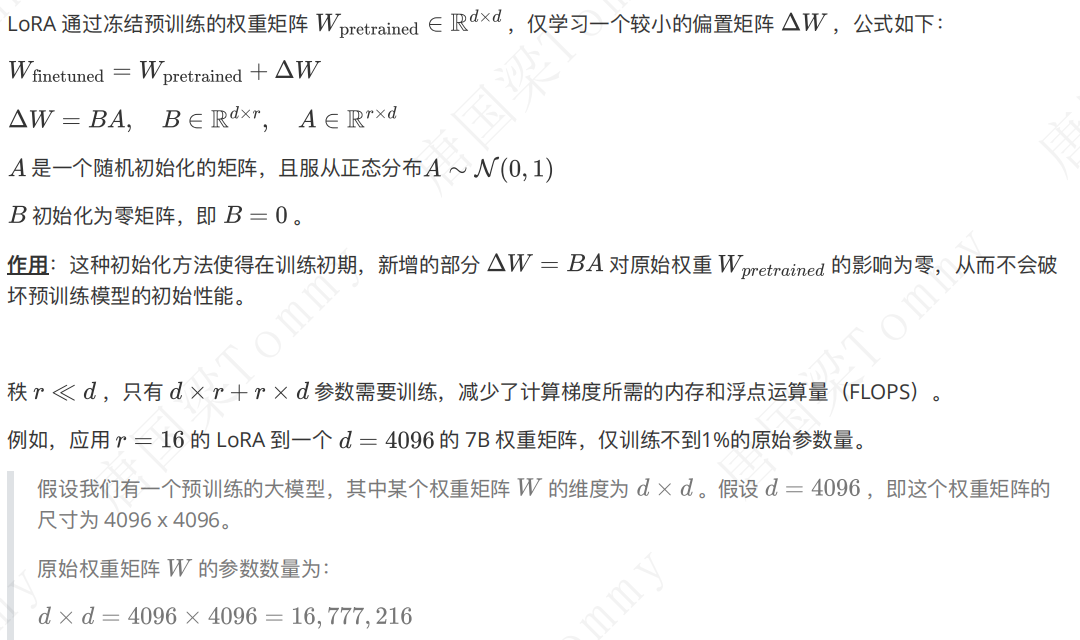

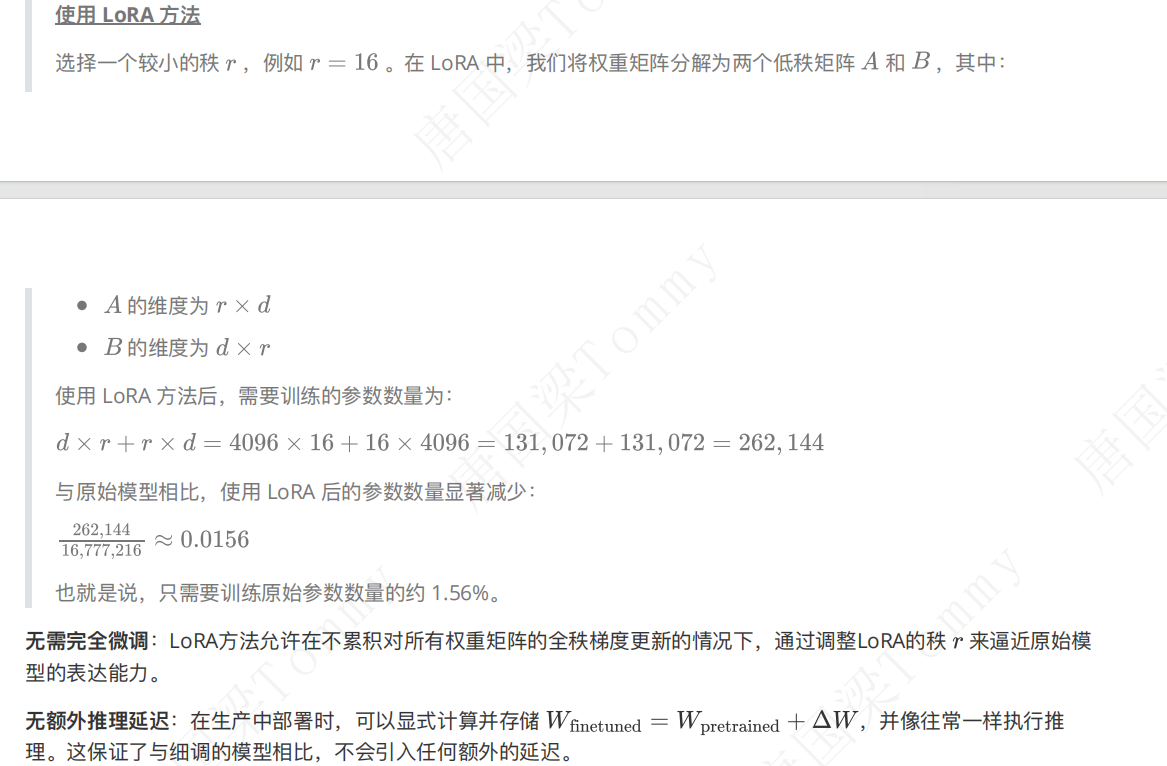

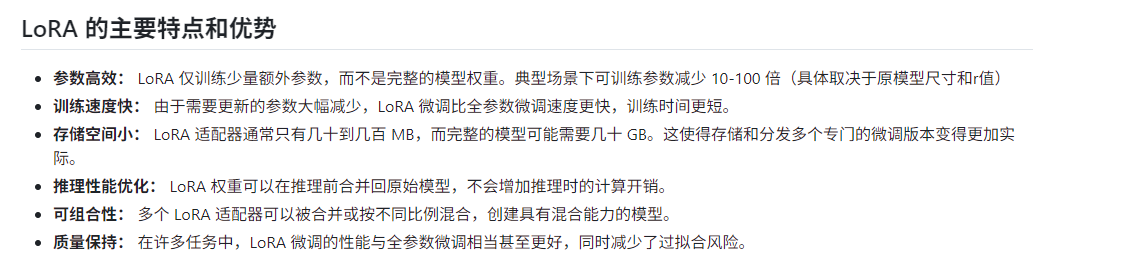

### 低秩矩阵的梯度更新

低秩矩阵分解是一种将高维矩阵近似为两个低维矩阵乘积的技术，常用于数据降维、压缩、推荐系统等领域。

**步骤1：理解目标**  
我们有一个高维矩阵 $\Delta W$ ，希望将其近似为两个低维矩阵$A$和$B$的乘积，即$\Delta W \approx BA$。

**步骤2：设定矩阵维度**  
假设 $\Delta W$是一个$d \times d$的矩阵。我们选择一个较小的整数 $r$，使得 $r \ll d$ 。矩阵 $A$ 的维度将是 $d \times r$ ，矩阵 $B$ 的维度将是 $r \times d$ 。

**步骤3：矩阵初始化**  
- 初始化矩阵 $A$ 和 $B$ 。可以使用随机初始化、正态分布初始化等方法。例如：  
  - $A \sim \mathcal{N}(0, \sigma^2)$ ，表示矩阵 $A$ 的每个元素都是从均值为0、方差为 $\sigma^2$ 的正态分布中随机抽取的。  
  - $B$ 初始化为零矩阵，即 $B = 0$ 。  

**步骤4：矩阵乘积**  
- 通过矩阵乘积 $BA$ ，可以得到一个近似的 $d \times d$ 矩阵：  
  $
  W' = BA
  $
  其中 $W' \approx \Delta W$ 。

**步骤5：优化和训练**  
- 在训练过程中，通过优化算法（如梯度下降），不断调整矩阵 $A$ 和 $B$ 的值，使得 $W'$ 更加接近于 $\Delta W$ 。  
- 损失函数通常是衡量 $\Delta W$ 与 $W'$ 之间差距的一个函数，例如均方误差：  
  $
  L = \| \Delta W - BA \|_F^2
  $
  

**步骤6：更新规则**  
- 通过优化算法计算损失函数关于 $A$ 和 $B$ 的梯度，并更新 $A$ 和 $B$ 的值。例如，使用梯度下降法更新规则如下：
  
  $
  A \leftarrow A - \eta \frac{\partial L}{\partial A}
  $
  
  $
  B \leftarrow B - \eta \frac{\partial L}{\partial B}
  $  

  其中 $\eta$ 是学习率。


In [11]:
import numpy as np
#初始化矩阵W d=4
W = np.array([[4, 3, 2, 1],
              [2, 2, 2, 2],
              [1, 3, 4, 2],
              [0, 1, 2, 3]])

#矩阵的维度
d = W.shape[0]
#秩
r = 2
#随机初始化A和B
np.random.seed(666)
#A服从标准正态分布
A = np.random.randn(d,r)
B = np.zeros((r,d))

In [14]:
#定义超参数
lr = 0.01#学习率
epochs = 1000#训练轮次

In [15]:
#定义损失函数
def loss_function(W,A,B):
    W_approx = A @ B # np.matmul
    #均方差损失函数
    return np.linalg.norm(W-W_approx,"fro")**2

In [16]:
#定义梯度下降法
def descent(W,A,B,epochs):
    #
    loss_history=[]
    for i in range(epochs):
        #计算梯度
        W_approx = A @ B
        #计算损失函数关于矩阵A的梯度
        gd_A = -2 * (W - W_approx) @ B.T
        #计算损失函数关于矩阵B的梯度
        gd_B = -2 * A.T @ (W - W_approx)
        #使用梯度下降法更新A和B
        A -= lr * gd_A
        B -= lr * gd_B
        #计算当前损失
        loss = loss_function(W,A,B)
        loss_history.append(loss)
        if i %100==0:
            print(f"epoch:{i},loss:{loss}")
    
    return A,B,loss_history

In [17]:
A,B,loss_history = descent(W,A,B,epochs)

epoch:0,loss:87.65337013516582
epoch:100,loss:2.362029564122395
epoch:200,loss:2.3566410737509313
epoch:300,loss:2.356636663512506
epoch:400,loss:2.356636659479788
epoch:500,loss:2.3566366594760932
epoch:600,loss:2.3566366594760892
epoch:700,loss:2.3566366594760897
epoch:800,loss:2.3566366594760892
epoch:900,loss:2.3566366594760892


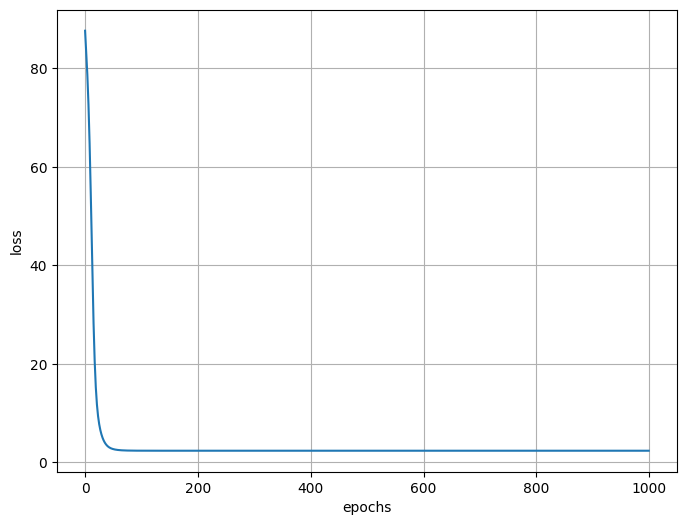

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.plot(loss_history,label="loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.grid(True)
plt.show()

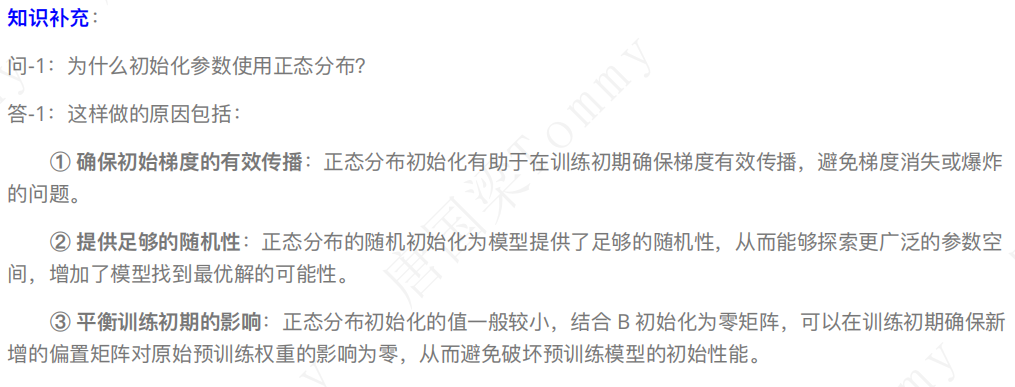

## 为什么矩阵B、A不能同时为0?

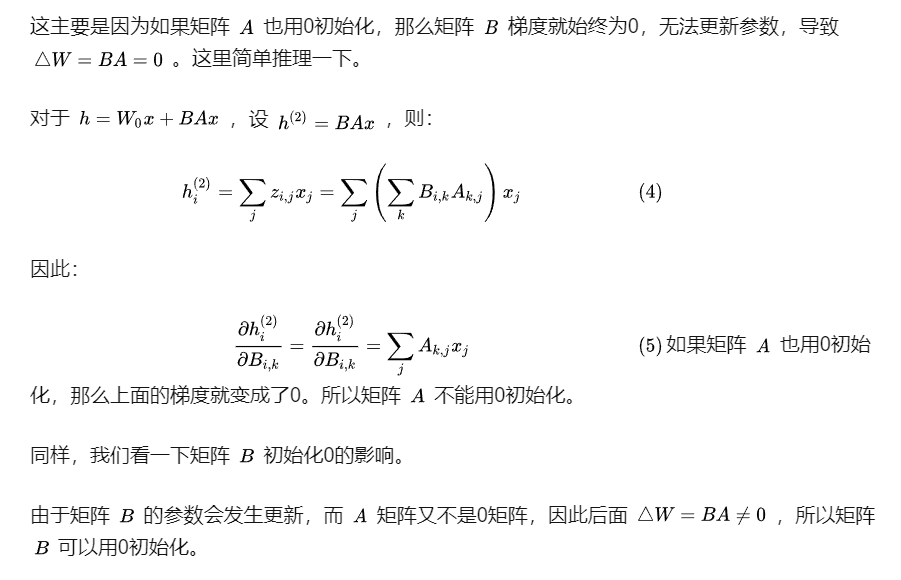

## 选择哪些权重矩阵进⾏适配？

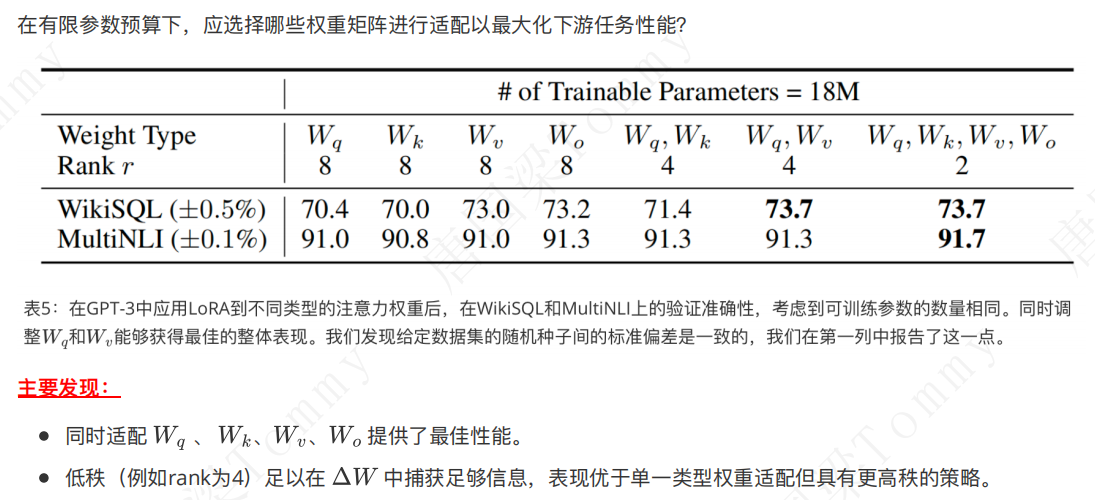

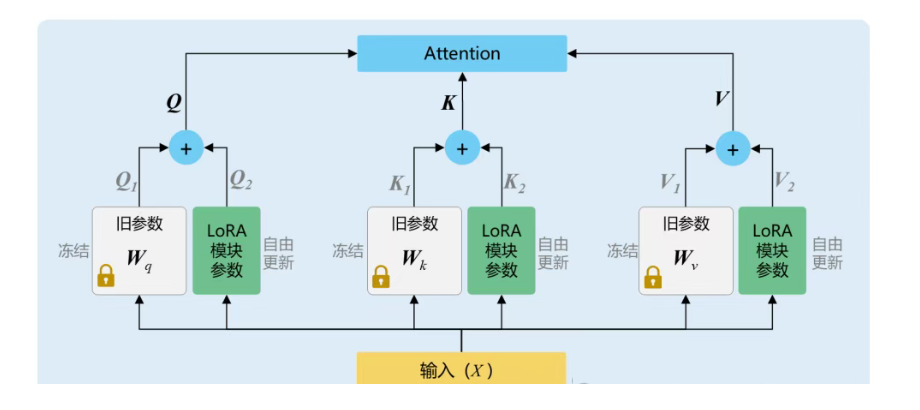

 * 为什么 LoRA 在 Q, K, V, O 上有效

LoRA（Low-Rank Adaptation）在 Transformer 模型的 Q（Query）、K（Key）、V（Value）和 O（Output）矩阵
上有效果的原因可以归结为这些矩阵在注意⼒机制中的核⼼作⽤以及 LoRA ⽅法在降低参数数量的同时保持或提升模
型性能的能⼒。具体原因如下：

+ Q（Query）矩阵：⽤于⽣成查询向量，决定模型在注意⼒机制中对输⼊的关注程度。
+ K（Key）矩阵：⽤于⽣成键向量，与查询向量计算相似度，帮助确定注意⼒分布。
+ V（Value）矩阵：⽤于⽣成数值向量，实际传递注意⼒机制计算的输出。
+ O（Output）矩阵：⽤于将多头注意⼒的输出合并并映射回原始维度。

Q、K 、V 和O 矩阵在信息传播和特征表示中起着关键作⽤：
+ 查询与键的交互： 和 的交互决定了注意⼒分布，影响模型对输⼊序列的不同部分的关注度。
+ 数值的加权求和： 矩阵通过加权求和操作，将注意⼒分布转化为具体的输出。
+ 多头输出的整合： 矩阵整合多头注意⼒的输出，提供最终的特征表示。

LoRA 通过将权重矩阵分解为两个低秩矩阵（例如 W=BA），减少了参数数量，降低了计算和存储成本，同时保
持模型性能：
+ 参数压缩：Q 、K 、V 和O 矩阵通常包含⼤量参数，LoRA 的低秩分解显著减少了需要优化的参数数量。
+ 性能保持：低秩矩阵能够捕捉到原始矩阵的主要信息，确保模型性能不受显著影响。

 ## LoRA中的最优秩 r 的选择?     
测试数据集：
WikiSQL：SQL 查询数据集
MultiNLI：自然语言推理数据集

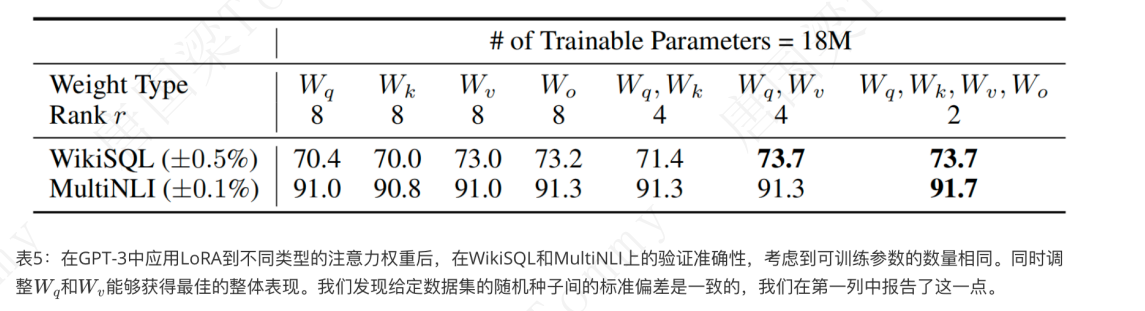

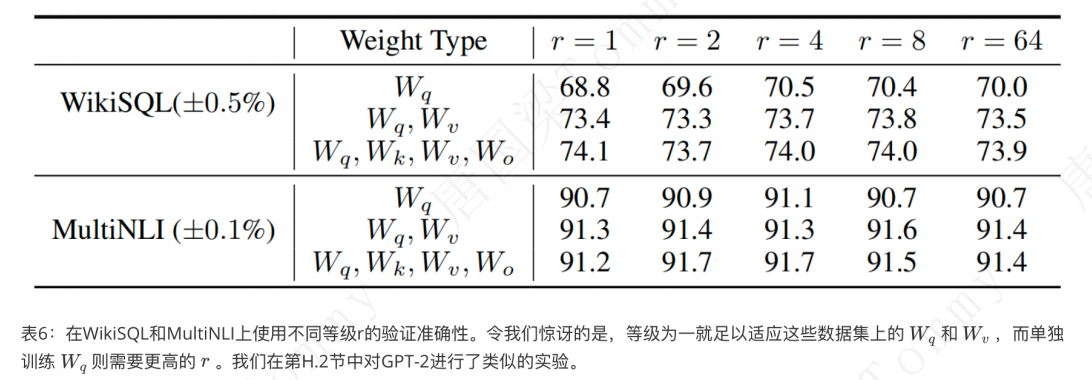

+ LoRA 即使在⾮常⼩的秩 下也展现出了竞争⼒的性能。
+ 在同时适配 和 时⽐仅适配 表现更好。
+ 增加 并没有覆盖更多有意义的⼦空间，说明低秩适配矩阵已⾜够。

## LoRA可以应⽤到模型中的哪些层？

LoRA（Low-Rank Adaptation）可以插⼊到模型的多个地⽅，具体取决于需要微调的模型部分和任务要求。以下是⼀
些常⻅的插⼊位置及其原因：

线性层（全连接层）<br>
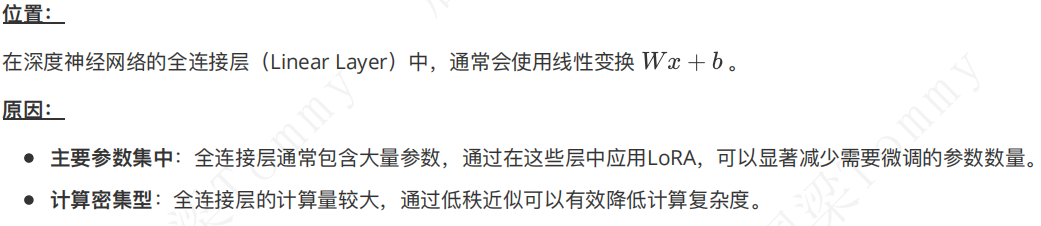

注意⼒层<br>
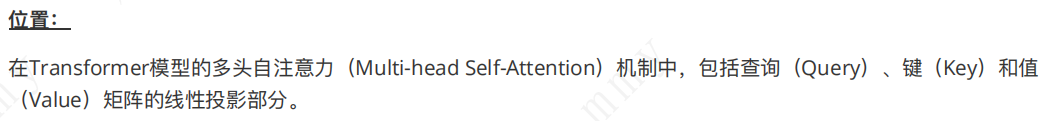<br>
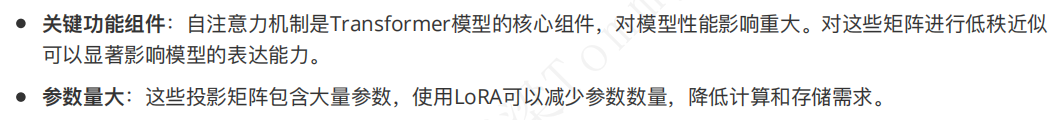<br>

嵌⼊层<br>
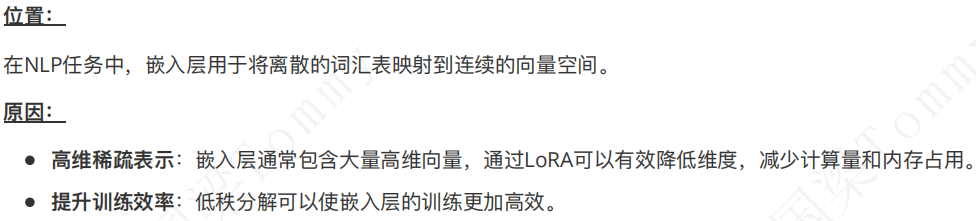

## Hugging Face PEFT 介绍

Hugging Face 的 PEFT（Parameter-Efficient Fine-Tuning）库是一个用于高效微调预训练语言模型的工具包，目前支持Prefix Tuning、Prompt Tuning、PTuningV1、PTuningV2、Adapter、LoRA、AdaLoRA，LoRA等微调方法。它专注于在保持高性能的同时，减少微调过程中需要更新的参数数量，从而降低计算成本和内存需求。

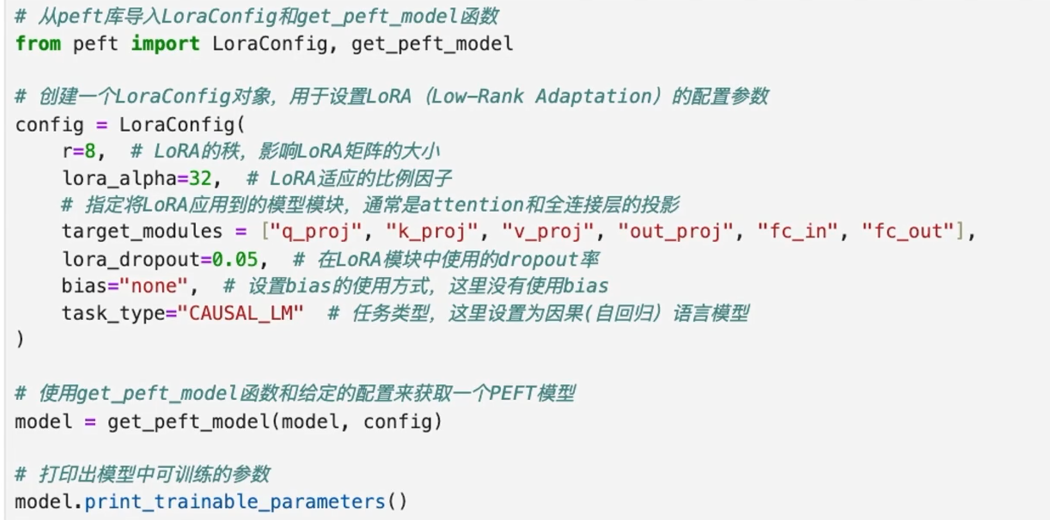

https://mp.weixin.qq.com/s/FHck8ip2cdOgs7Sah8szUg

https://huggingface.co/datasets/FreedomIntelligence/medical-o1-reasoning-SFT

## 优化器与帝都检查点

In [ ]:
'''
# 梯度检查点配置
model.enable_input_require_grads() # 开启梯度检查点时，要执行该方法
输入的embedding层通常也被冻结
但是当启用 梯度检查点 时：
梯度检查点需要在反向传播时重新计算前向传播
重新计算需要输入数据能够追踪梯度
如果输入层的 requires_grad=False，梯度检查点会报错或无法正常工作
当你使用 LoRA（参数冻结）+ 梯度检查点（需要重新计算）时，
必须调用 enable_input_require_grads() 让输入层能够追踪梯度，
否则梯度检查点无法正常工作。

全参微调不需要，因为全参微调不冻结参数

gradient_checkpointing=True,  # 启用梯度检查点
gradient_checkpointing_kwargs={"use_reentrant": False},  # 非重入式检查点
工作流程：
前向传播：只保存关键检查点的激活值（比如每隔几层保存一次）
反向传播：
遇到需要的激活值时
从最近的检查点重新进行一次前向计算
用重新计算的激活值来计算梯度
内存节省：激活值的存储量大幅减少
'''

In [ ]:
'''

为啥需要动量
在实际训练中,7B个参数的梯度表现完全不同:

参数W₁ (某个attention的权重):
步骤1: gradient = 0.001
步骤2: gradient = 0.0009
步骤3: gradient = 0.0011
步骤4: gradient = 0.001
→ 非常稳定,方向明确

参数W₂ (某个FFN的权重):
步骤1: gradient = 0.5
步骤2: gradient = -0.3
步骤3: gradient = 0.7
步骤4: gradient = -0.4
→ 剧烈波动,方向不定

参数W₃ (某个LayerNorm的权重):
步骤1: gradient = 0.0001
步骤2: gradient = 0.00009
步骤3: gradient = 0.00011
步骤4: gradient = 0.0001
→ 梯度很小但稳定

如果用统一的学习率:
- W₁: 刚刚好
- W₂: 会震荡,不收敛
- W₃: 更新太慢,学不到东西



Adam的核心思想: 每个参数有自己的"自适应学习率"

对于参数Wᵢ:
- 一阶动量 mᵢ: 记录Wᵢ的梯度趋势(往哪个方向走)
- 二阶动量 vᵢ: 记录Wᵢ的梯度波动(走得稳不稳)


**一阶动量 (方向):**
m_t = β₁ × m_{t-1} + (1 - β₁) × gradient_t
      ↑                ↑
    0.9            0.1 (归一化系数)

作用: 记录梯度的"平均方向"

例子:
gradient历史: [-0.5, -0.4, -0.3, -0.5, -0.4]
m ≈ -0.42 (平均向负方向)

→ 告诉优化器: 应该往负方向走


**二阶动量 (波动):**
v_t = β₂ × v_{t-1} + (1 - β₂) × gradient_t²
      ↑                ↑
   0.999           0.001 (归一化系数)

例子1 - 稳定的梯度:
gradient历史: [-0.5, -0.48, -0.52, -0.49, -0.51]
gradient²: [0.25, 0.23, 0.27, 0.24, 0.26]
v ≈ 0.25 (小,稳定)
→ 可以用大学习率

例子2 - 波动的梯度:
gradient历史: [-2.0, 0.5, -1.5, 1.0, -1.8]
gradient²: [4.0, 0.25, 2.25, 1.0, 3.24]
v ≈ 2.15 (大,不稳定)
→ 应该用小学习率


**偏差修正:**
m̂_t = m_t / (1 - β₁ᵗ)
v̂_t = v_t / (1 - β₂ᵗ)

例子
β₁ = 0.9

步骤1 (t=1):
修正因子 = 1 - 0.9¹ = 1 - 0.9 = 0.1
m̂₁ = m₁ / 0.1 = m₁ × 10  ← 放大10倍!

步骤2 (t=2):
修正因子 = 1 - 0.9² = 1 - 0.81 = 0.19
m̂₂ = m₂ / 0.19 = m₂ × 5.26  ← 放大5.26倍

步骤100 (t=100):
修正因子 = 1 - 0.9¹⁰⁰ ≈ 1 - 0.00003 ≈ 1.0
m̂₁₀₀ = m₁₀₀ / 1.0 = m₁₀₀  ← 几乎不修正
规律: 
- 初期修正很大
- 后期几乎不修正

梯度恒定 = 1.0, β₁ = 0.9
步骤1: m₁ = 0.1 × 1.0 = 0.1
步骤2: m₂ = 0.9×0.1 + 0.1×1.0 = 0.19
步骤3: m₃ = 0.9×0.19 + 0.1×1.0 = 0.271
步骤4: m₄ = 0.9×0.271 + 0.1×1.0 = 0.344
步骤5: m₅ = 0.9×0.344 + 0.1×1.0 = 0.410

前5步平均: (0.1+0.19+0.271+0.344+0.410)/5 = 0.263
→ 只有真实梯度的26%!

**参数更新:**
W_t = W_{t-1} - lr × m̂_t / (√v̂_t + ε)

W₁: 稳定 → √v₁小 → 实际学习率大 → 快速更新
W₂: 波动 → √v₂大 → 实际学习率小 → 谨慎更新
W₃: 稳定但小 → 通过m₃累积方向 → 逐步更新

**Adam vs SGD Momentum的区别:**
1. Adam有归一化系数 (1-β),动量不会无限累积
2. Adam有二阶动量,可以自适应调整学习率
3. Adam有偏差修正,避免初期偏向0



**标准Momentum公式 (SGD + Momentum):**

动量更新:
v_t = μ × v_{t-1} + gradient_t
      ↑     ↑         ↑
  动量系数 历史动量   当前梯度

参数更新:
W_t = W_{t-1} - learning_rate × v_t
                                 ↑
                              使用动量

其中:
- μ (mu): 动量系数,通常是0.9
- v: 动量(velocity,速度),会累积历史梯度
- gradient: 当前梯度

**重要**: 这个公式中动量会不断累积,使得更新加速!

---

### 具体计算示例

假设 μ = 0.9, learning_rate = 0.01

初始: W = 1.0, v = 0

步骤1:
  gradient = -0.5
  v = 0.9 × 0 + (-0.5) = -0.5
  W = 1.0 - 0.01 × (-0.5) = 1.005

步骤2:
  gradient = -0.4
  v = 0.9 × (-0.5) + (-0.4) = -0.85
  W = 1.005 - 0.01 × (-0.85) = 1.0135
  
步骤3:
  gradient = -0.3
  v = 0.9 × (-0.85) + (-0.3) = -1.065
  W = 1.0135 - 0.01 × (-1.065) = 1.02415

**观察**: v的绝对值越来越大(从0.5→0.85→1.065),参数更新越来越快!
这就是动量的"加速"效果。

---

### 动量的本质: 历史梯度的加权和

v_t = μ × v_{t-1} + gradient_t

递归展开:
v_t = gradient_t 
    + μ × gradient_{t-1}
    + μ² × gradient_{t-2}
    + μ³ × gradient_{t-3}
    + ...

当 μ = 0.9 时,各梯度的权重:
- 当前梯度(t):     1.0
- 上一步(t-1):     0.9
- 上上步(t-2):     0.81
- 三步前(t-3):     0.729
- 更早的梯度:      越来越小,逐渐遗忘

**意义**: 动量 = 记住过去的方向,但越远的影响越小

---

### 动量的稳态分析

如果梯度保持不变 (gradient = g):

v₁ = 0.9 × 0 + g = g
v₂ = 0.9 × g + g = 1.9g
v₃ = 0.9 × 1.9g + g = 2.71g
...
v_∞ = g / (1 - 0.9) = 10g

**结论**: 
- 动量最终会稳定在 v = gradient / (1 - μ)
- 当 μ = 0.9 时,稳态动量是梯度的10倍!
- 这就是为什么使用动量后,学习率通常要调小

---

### 动量的三大作用

**作用1: 加速收敛**
- 当梯度方向一致时,动量不断累积
- 参数更新越来越快
- 在平缓区域快速前进

**作用2: 平滑震荡**
- 当梯度方向改变时,动量起到平滑作用
- 减少来回震荡
- 对噪声不敏感

**作用3: 逃离局部最优**
- 即使当前梯度为0(局部最优点)
- 历史动量 v ≠ 0
- 靠"惯性"继续前进,可能逃离局部最优

---

### PyTorch中的实现

import torch.optim as optim

# SGD + Momentum
optimizer = optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9  # 动量系数 μ
)---



### 为什么训练需要存储动量?

**7B参数的模型:**

使用SGD + Momentum:
- 参数W: 7B个数 → 28 GB
- 梯度: 7B个数 → 28 GB
- 动量v: 7B个数 → 28 GB
- **总计: 84 GB**

使用Adam:
- 参数W: 7B个数 → 28 GB
- 梯度: 7B个数 → 28 GB
- 一阶动量m: 7B个数 → 28 GB
- 二阶动量v: 7B个数 → 28 GB
- **总计: 112 GB**

**为什么每个参数都要存?**
因为每个参数的梯度历史不同,需要独立的动量来记录!

---

### 总结

- **SGD Momentum**: v_t = μ × v_{t-1} + gradient_t (会累积)
- **Adam Momentum**: m_t = β × m_{t-1} + (1-β) × gradient_t (有归一化)
- **动量的作用**: 加速、平滑、逃离局部最优
- **显存占用**: 每个参数都需要独立的动量存储
'''